In [6]:
from pickle import load
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from csv import reader

lets see if my child is smart

first, load the new data

In [7]:
with open("new_data/new_data.csv", mode='r') as file:
    data = list(reader(file))[1:]

answers = [float(data[row][0]) for row in range(3, len(data))]
values = []
for row in range(len(answers)):
    values.append((
                float(data[row][0]),
                int(data[row][1]),
                #float(data[row][2]),
                #float(data[row][3]),  removed the daylight time and the total rain sum, and the model predicts way better now!
                #float(data[row][4]),
                float(data[row][5]),
                float(data[row][6]),
    
                float(data[row+1][0]),
                int(data[row+1][1]),
                #float(data[row+1][2]),
                #float(data[row+1][3]),
                #float(data[row+1][4]),
                float(data[row+1][5]),
                float(data[row+1][6]),
    
                float(data[row+2][0]),
                int(data[row+2][1]),
                #float(data[row+2][2]),
                #float(data[row+2][3]),
                #float(data[row+2][4]),
                float(data[row+2][5]),
                float(data[row+2][6])
            ))
# i know it would be better to use a loop but im getting desperate(its late)
        

now, awaken my child from the sacred file

In [8]:

with open("MyVeryOwnModelThatImVeryProudOvAndHelloIfUrReadingThis.pkl", mode='rb') as file:
    model = load(file)

with open("MyScalerForMyVeryOwnModelYayHappyFace", mode='rb') as file:
    scaler = load(file)


test the child

In [9]:
values = scaler.transform(values)

preds = model.predict(values)
preds *= 1.1
#evaluate model
r2 = r2_score(answers, preds)
mae = mean_absolute_error(answers, preds)
rmse = root_mean_squared_error(answers, preds)

print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

R2 Score: 0.5934
MAE: 38.3588
RMSE: 52.7933


hey! my child is not failing! WHAHOOOO!!! 🥳🎉🎉🎉🎉

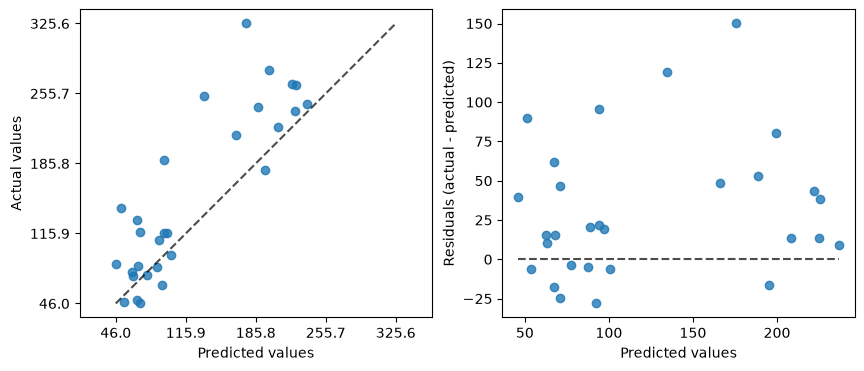

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import PredictionErrorDisplay

fig, axs = plt.subplots(ncols=2, figsize=(10, 4))
PredictionErrorDisplay.from_predictions(answers, preds, kind="actual_vs_predicted", ax=axs[0])

PredictionErrorDisplay.from_predictions(answers, preds, kind="residual_vs_predicted", ax=axs[1])

plt.show()